# Figure 4 | Predictive FC organization differed across IAT ranges

**Figure contract**

- **Visual argument.** **A** 每折选边数量；**B** 阈值下保留边数；**C** 两组 signed Haufe 网络块；**D** 基于 C 数值的 FPN 配置；**E** 全部 36 块 high−low 差值。
- **Data sources.** 全部输入都在 `2_Computations/` 下：`2_Computations/CPM_nestedCV_LOOCV/`（每组 22,791 条 FC 的 Haufe 汇总、选边向量、折结果 pkl、10,000 次分块置换零分布）与 `2_Computations/CPM_classic_Haufe/`（经典 CPM 的 10,000 次组内置换零分布）；本 notebook 把 ROI 元数据与其它派生表一起写到 `3_Visualizations/Visualization_Figure4/`（`Haufe_ROI_metadata.csv`），供 Figure 3 直接读取（Figure 3 需在本 notebook 之后运行）。
- **Recomputation.** 边级 Haufe slope、网络块求和、组内置换与 BH-FDR、跨范围特异性检验全部在本 notebook 内重新计算（cell 2–7），cell 8 只负责作图。
- **Intermediate data.** 派生表与分析清单写入 `3_Visualizations/Visualization_Figure4/`（与本 notebook 同名）。
- **Output.** `3_Visualizations/results_figures/Figure4.png`（300 dpi）和 `3_Visualizations/results_figures/Figure4.svg`；图也在 notebook 内显示。


## 1. 路径与分析参数

In [1]:
import os
import sys

from pathlib import Path
import json, pickle, warnings, hashlib
import numpy as np
import pandas as pd
def display(x):
    """Stand-in for IPython.display.display that prints in plain Python."""
    try:
        print(x.to_string())
    except AttributeError:
        print(x)

# ---------------------------------------------------------------------------
# 官方包路径（全部由本 notebook 的位置推导，与工作目录无关）
# ---------------------------------------------------------------------------
#     Visualization_Figure_official/
#     ├── 0_mylib/                Python 辅助模块（biox/）
#     ├── 1_Inputs/               原始数据：量表汇总表、两套时间序列
#     ├── 2_Computations/         上游 CPM 分析产物（GMM / LOOCV / 置换零分布）
#     └── 3_Visualizations/       本项目的 notebook、中间数据与出图结果
#         ├── Visualization_Figure4/  本 notebook 产生的中间数据
#         └── results_figures/        出图结果（PNG 300 dpi + SVG）
PACKAGE_ROOT = next(
    (base for base in [Path.cwd(), *Path.cwd().parents]
     if (base / '2_Computations').is_dir()),
    None,
)
if PACKAGE_ROOT is None:
    raise FileNotFoundError(
        'Could not locate the official package: it must hold 2_Computations/.'
)
LIB_ROOT = PACKAGE_ROOT / '0_mylib'            # Python 辅助模块（biox/）
INPUT_ROOT = PACKAGE_ROOT / '1_Inputs'         # 原始数据
COMPUTE_ROOT = PACKAGE_ROOT / '2_Computations' # 上游 CPM 分析产物
VIZ_ROOT = PACKAGE_ROOT / '3_Visualizations'   # notebook / 中间数据 / 出图结果
RESULTS_DIR = VIZ_ROOT / 'results_figures'
OUTPUT_DIR = VIZ_ROOT / 'Visualization_Figure4'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(LIB_ROOT))
from biox.fcmat import fc_edges_module_pair_sum

from typing import Mapping, Optional

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle



SOURCE_DIR = COMPUTE_ROOT / 'CPM_nestedCV_LOOCV'
# 中间数据（派生表、分析清单）写进与本 notebook 同名的文件夹
RESULT_DIR = OUTPUT_DIR
RESULT_DIR.mkdir(parents=True, exist_ok=True)
PERM_DIR = SOURCE_DIR / ('figure8A_style_haufe_block_permutation_LOOCV_10000perm_'
    'sitewise_residY_threaded_foldAlpha_Hn461_4d92fba0c22b_Ln653_a289cdb20536')
GROUPS = ['highIAT', 'lowIAT']
NETWORKS = ['Vis', 'SMN', 'DAN', 'VAN', 'Lim', 'FPN', 'DMN', 'Subcortex']
N_ROIS, N_EDGES = 214, 22791
STABLE_THRESHOLD = 0.80
THRESHOLD_GRID = np.round(np.arange(1, 21) * 0.05, 2)
FDR_ALPHA = 0.05
pd.set_option('display.max_columns', 24)
pd.set_option('display.width', 180)
pd.set_option('display.precision', 6)

class ProjectNumpyUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        if int(np.__version__.split('.')[0]) < 2 and module.startswith('numpy._core'):
            module = module.replace('numpy._core', 'numpy.core', 1)
        return super().find_class(module, name)

def bh_fdr(p_values):
    p_values = np.asarray(p_values, dtype=float)
    q_values = np.full_like(p_values, np.nan)
    valid = np.isfinite(p_values)
    p = p_values[valid]
    if p.size == 0:
        return q_values
    order = np.argsort(p)
    q_ranked = p[order] * p.size / np.arange(1, p.size + 1)
    q_ranked = np.clip(np.minimum.accumulate(q_ranked[::-1])[::-1], 0, 1)
    q_values[np.flatnonzero(valid)[order]] = q_ranked
    return q_values

def descriptive_pearson(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 2 or not (np.isfinite(x).all() and np.isfinite(y).all()):
        warnings.warn('相关未计算：点数不足或存在非有限值；未静默删除边。')
        return np.nan
    if np.ptp(x) == 0 or np.ptp(y) == 0:
        warnings.warn('相关未计算：至少一个向量方差为零。')
        return np.nan
    return float(np.corrcoef(x, y)[0, 1])


## 2. 读取与完整性核查

按 edge_idx 对齐全部 22,791 条 FC，核对 CSV、NPZ 和 CV 选边记录；确认 461/653 折及原组内置换来源。

In [2]:
edge_tables, cv_records, permutation_data, provenance = {}, {}, {}, []
fold_rows = []
roi_i, roi_j = np.triu_indices(N_ROIS, k=1)
metadata_cols = ['edge_idx', 'roi_i', 'roi_j', 'roi_i_name', 'roi_j_name', 'net_i', 'net_j', 'network_pair']
for group in GROUPS:
    edge_path = SOURCE_DIR / f'CPM_nestedCV_{group}_haufe_all_FCs.csv'
    vector_path = SOURCE_DIR / f'CPM_nestedCV_{group}_haufe_vectors.npz'
    cv_path = SOURCE_DIR / f'CPM_nestedCV_{group}_cv_results.pkl'
    null_path = PERM_DIR / group / 'figure8A_style_block_permutation_null.npz'
    metadata_path = PERM_DIR / group / 'figure8A_style_metadata.json'
    edges = pd.read_csv(edge_path).sort_values('edge_idx').reset_index(drop=True)
    assert len(edges) == N_EDGES and not edges.edge_idx.duplicated().any()
    np.testing.assert_array_equal(edges.edge_idx, np.arange(N_EDGES))
    np.testing.assert_array_equal(edges.roi_i, roi_i)
    np.testing.assert_array_equal(edges.roi_j, roi_j)
    assert edges[metadata_cols].notna().all().all()
    with np.load(vector_path) as vectors:
        for column, key in [('haufe_selection_count', 'selection_count'),
                            ('haufe_selection_freq', 'selection_freq'),
                            ('haufe_corr_selected_mean_all_folds', 'haufe_corr_selected_mean_all_folds'),
                            ('haufe_corr_abs_selected_mean_all_folds', 'haufe_corr_abs_selected_mean_all_folds')]:
            assert vectors[key].shape == (N_EDGES,) and np.isfinite(vectors[key]).all()
            np.testing.assert_allclose(edges[column], vectors[key], rtol=1e-10, atol=1e-14)
    with cv_path.open('rb') as handle:
        cv = ProjectNumpyUnpickler(handle).load()
    records = cv[4]
    n_valid_values = edges.n_valid_haufe_folds.unique()
    assert len(n_valid_values) == 1 and n_valid_values[0] == len(records)
    assert len({(r['repeat'], r['fold']) for r in records}) == len(records)
    selected_count = np.zeros(N_EDGES, dtype=int)
    for record in records:
        idx = np.asarray(record['edge_idx'], dtype=int)
        assert len(idx) == len(np.unique(idx)) and ((idx >= 0) & (idx < N_EDGES)).all()
        selected_count[idx] += 1
        fold_rows.append(dict(group=group, repeat=record['repeat'], fold=record['fold'],
            n_selected_edges=len(idx), valid_haufe=True,
            validity_source='all CV folds valid in saved Haufe summary; edge counts cross-checked'))
    np.testing.assert_array_equal(selected_count, edges.haufe_selection_count)
    np.testing.assert_allclose(selected_count / len(records), edges.haufe_selection_freq, atol=1e-14)
    with np.load(null_path) as saved:
        null = {k: saved[k].copy() for k in saved.files}
    metadata = json.loads(metadata_path.read_text())
    assert metadata['shuffle_within_site'] is True
    assert 'fold-specific' in metadata['permutation'] and metadata['N'] == len(records)
    assert metadata['n_permutations'] == 10000
    assert null['block_value'].shape == (10000, 36)
    np.testing.assert_array_equal(np.sort(null['permutation_index']), np.arange(10000))
    assert np.isfinite(null['block_value']).all()
    edge_tables[group], cv_records[group], permutation_data[group] = edges, records, null
    for path in [edge_path, vector_path, cv_path, null_path, metadata_path]:
        provenance.append(dict(group=group, path=str(path.relative_to(PACKAGE_ROOT)),
            bytes=path.stat().st_size, sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
    print(f'{group}: {len(records)} 个有效折；{N_EDGES} 条对齐边；'
          f"置换实际 {len(null['permutation_index'])} 次（metadata: {metadata['n_permutations']} 次）")

pd.testing.assert_frame_equal(edge_tables['highIAT'][metadata_cols], edge_tables['lowIAT'][metadata_cols])
base = edge_tables['highIAT']
roi_metadata = pd.concat([
    base[['roi_i', 'roi_i_name', 'net_i']].set_axis(['roi', 'roi_name', 'network'], axis=1),
    base[['roi_j', 'roi_j_name', 'net_j']].set_axis(['roi', 'roi_name', 'network'], axis=1)
]).drop_duplicates().sort_values('roi').reset_index(drop=True)
assert len(roi_metadata) == N_ROIS and not roi_metadata.roi.duplicated().any()
assert set(roi_metadata.network) == set(NETWORKS)
roi_network = roi_metadata.set_index('roi').network
fold_counts = pd.DataFrame(fold_rows)


highIAT: 461 个有效折；22791 条对齐边；置换实际 10000 次（metadata: 10000 次）


lowIAT: 653 个有效折；22791 条对齐边；置换实际 10000 次（metadata: 10000 次）


## 3. 特征数量与稳定性（A–B）

In [3]:
density_rows = []
for group in GROUPS:
    counts = fold_counts.loc[fold_counts.group == group, 'n_selected_edges']
    freq = edge_tables[group].haufe_selection_freq.to_numpy()
    q1, q3 = counts.quantile([.25, .75])
    density_rows.append(dict(group=group, n_valid_folds=len(counts),
        selected_edges_mean=counts.mean(), selected_edges_median=counts.median(),
        selected_edges_q1=q1, selected_edges_q3=q3,
        selected_edges_min=counts.min(), selected_edges_max=counts.max(),
        n_edges_freq_ge_0_80=int((freq >= STABLE_THRESHOLD).sum())))
density = pd.DataFrame(density_rows)
display(density)

paired_edges = base[metadata_cols].copy()
for group, prefix in [('highIAT','high'), ('lowIAT','low')]:
    edges = edge_tables[group]
    paired_edges[f'{prefix}_selection_freq'] = edges.haufe_selection_freq.to_numpy()
    paired_edges[f'{prefix}_selection_count'] = edges.haufe_selection_count.to_numpy()
frequency_high = paired_edges.high_selection_freq.to_numpy()
frequency_low = paired_edges.low_selection_freq.to_numpy()
threshold_rows = []
for threshold in THRESHOLD_GRID:
    high, low = frequency_high >= threshold, frequency_low >= threshold
    shared, union = int((high & low).sum()), int((high | low).sum())
    threshold_rows.append(dict(threshold=threshold, high_n=int(high.sum()), low_n=int(low.sum()),
        shared_n=shared, union_n=union, jaccard=shared/union if union else np.nan,
        high_low_ratio=high.sum()/low.sum() if low.any() else np.nan))
curve = pd.DataFrame(threshold_rows)
assert len(curve) == 20
assert (np.diff(curve.high_n) <= 0).all() and (np.diff(curve.low_n) <= 0).all()
print(f'阈值 0.05–1.00；high/low 保留边数比值 {curve.high_low_ratio.min():.2f}–{curve.high_low_ratio.max():.2f}')
display(curve)


     group  n_valid_folds  selected_edges_mean  selected_edges_median  selected_edges_q1  selected_edges_q3  selected_edges_min  selected_edges_max  n_edges_freq_ge_0_80
0  highIAT            461           318.219089                  319.0              307.0              327.0                 210                 476                   286
1   lowIAT            653            75.402757                   75.0               74.0               77.0                  67                  89                    71
阈值 0.05–1.00；high/low 保留边数比值 2.73–4.41
    threshold  high_n  low_n  shared_n  union_n  jaccard  high_low_ratio
0        0.05     390     92         0      482      0.0        4.239130
1        0.10     367     88         0      455      0.0        4.170455
2        0.15     355     83         0      438      0.0        4.277108
3        0.20     340     81         0      421      0.0        4.197531
4        0.25     333     76         0      409      0.0        4.381579
5        0.30

## 4. 跨范围特异性：保留数值分析，不再绘图

In [4]:
frequency_r = descriptive_pearson(frequency_high, frequency_low)
primary_overlap = curve.loc[curve.threshold == STABLE_THRESHOLD].iloc[0]
cross_rows, cross_edge_tables = [], []
for source, target, source_group, target_group in [
    ('high','low','highIAT','lowIAT'), ('low','high','lowIAT','highIAT')]:
    detail = paired_edges.loc[paired_edges[f'{source}_selection_freq'] >= STABLE_THRESHOLD].copy()
    values = detail[f'{target}_selection_freq'].to_numpy()
    detail['source_group'], detail['target_group'] = source_group, target_group
    detail['target_selection_count'] = detail[f'{target}_selection_count']
    detail['target_valid_folds'] = len(cv_records[target_group])
    cross_edge_tables.append(detail)
    cross_rows.append(dict(source_group=source_group, target_group=target_group,
        source_stable_n=len(values), target_never_selected_n=int((values == 0).sum()),
        target_ever_selected_n=int((values > 0).sum()),
        target_max_selection_count=int(detail.target_selection_count.max()),
        target_valid_folds=len(cv_records[target_group]), target_frequency_max=float(values.max())))
cross_summary = pd.DataFrame(cross_rows)
cross_edges = pd.concat(cross_edge_tables, ignore_index=True)
print(f'全边入选频率相关 r={frequency_r:.7f}；主阈值共有边={int(primary_overlap.shared_n)}；Jaccard={primary_overlap.jaccard:.3f}')
display(cross_summary)
display(cross_edges.loc[cross_edges.target_selection_count > 0,
    ['source_group','target_group','edge_idx','roi_i_name','roi_j_name','target_selection_count','target_valid_folds']])


全边入选频率相关 r=-0.0073357；主阈值共有边=0；Jaccard=0.000
  source_group target_group  source_stable_n  target_never_selected_n  target_ever_selected_n  target_max_selection_count  target_valid_folds  target_frequency_max
0      highIAT       lowIAT              286                      285                       1                           1                 653              0.001531
1       lowIAT      highIAT               71                       71                       0                           0                 461              0.000000
    source_group target_group  edge_idx                            roi_i_name                       roi_j_name  target_selection_count  target_valid_folds
272      highIAT       lowIAT     21058  7Networks_RH_SalVentAttn_FrOperIns_4  7Networks_RH_Default_PFCdPFCm_3                       1                 653


## 5. Signed Haufe 网络块及组内推断（C）

对边级跨折平均 signed Haufe 按块求和，再除以块内全部可能边数。原有 10,000 次组内置换为双侧检验；保留 BH-FDR 结果，避免将未校正 P 解释为校正后显著。

In [5]:
def _find_classic_dir():
    """经典 CPM 的 10,000 次组内置换零分布（唯一规范位置）。"""
    candidate = COMPUTE_ROOT / 'CPM_classic_Haufe'
    if candidate.is_dir():
        return candidate
    raise FileNotFoundError(
        f'CPM_classic_Haufe not found at {candidate}.')

CLASSIC_DIR = _find_classic_dir()
classic_data = {}
for group in GROUPS:
    arrays, indices, reference = [], [], None
    for path in sorted(CLASSIC_DIR.glob(f'{group}_null_*.npz')):
        with np.load(path) as z:
            labels = z['labels'].astype(str)
            if reference is None:
                reference = z['observed'][1].copy()
                reference_labels = labels.copy()
            np.testing.assert_array_equal(labels, reference_labels)
            np.testing.assert_allclose(z['observed'][1], reference)
            arrays.append(z['values'][:, 1, :].copy())
            indices.extend(z['indices'].tolist())
    order = np.argsort(indices)
    np.testing.assert_array_equal(np.asarray(indices)[order], np.arange(10000))
    distribution = np.concatenate(arrays)[order]
    assert distribution.shape == (10000, 36) and np.isfinite(distribution).all()
    p = (1 + (np.abs(distribution) >= np.abs(reference)).sum(axis=0)) / 10001
    classic_data[group] = dict(network_block_labels=reference_labels,
        observed_block_value=reference, block_value=distribution,
        p_two_sided=p, q_fdr_two_sided=bh_fdr(p))
    provenance.append(dict(group=group, source=str(CLASSIC_DIR),
        mapping='classic_slope', n_permutations=10000))
    for path in sorted(CLASSIC_DIR.glob(f'{group}_null_*.npz')):
        provenance.append(dict(group=group, path=str(path),
            bytes=path.stat().st_size,
            sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
    print(f'{group}: 经典 slope 零分布 {distribution.shape[0]} x {distribution.shape[1]}；'
          f"最小双侧 P = {p.min():.4f}")


highIAT: 经典 slope 零分布 10000 x 36；最小双侧 P = 0.0150


lowIAT: 经典 slope 零分布 10000 x 36；最小双侧 P = 0.0538


## 6. Results 数值核对与保存

检查正文报告值与当前计算的一致性。保存当前分析清单，旧版探索性文件不作为本版结果来源。

In [6]:
possible = fc_edges_module_pair_sum(np.ones(N_EDGES), base[['roi_i','roi_j']], roi_network).loc[NETWORKS,NETWORKS]
assert sum(possible.iloc[i,j] for i in range(8) for j in range(i,8)) == N_EDGES
block_tables, block_matrices = [], {}
for group in GROUPS:
    edges, null = edge_tables[group], classic_data[group]
    sums = fc_edges_module_pair_sum(edges.haufe_slope_selected_mean_all_folds,
                                    edges[['roi_i','roi_j']], roi_network).loc[NETWORKS,NETWORKS]
    matrix = sums / possible
    block_matrices[group] = matrix
    block_rows = []
    for i, a in enumerate(NETWORKS):
        for b in NETWORKS[i:]:
            block_rows.append(dict(group=group, network_1=a, network_2=b, block_label=f'{a}-{b}',
                n_possible_edges=int(possible.loc[a,b]), observed_block_value=matrix.loc[a,b]))
    blocks = pd.DataFrame(block_rows)
    assert len(blocks) == 36 and blocks.block_label.nunique() == 36
    null_labels = list(null['network_block_labels'])
    assert len(set(null_labels)) == 36 and set(null_labels) == set(blocks.block_label)
    order = [null_labels.index(label) for label in blocks.block_label]
    observed = blocks.observed_block_value.to_numpy()
    np.testing.assert_allclose(observed, null['observed_block_value'][order], rtol=1e-9, atol=1e-12)
    reference_observed = null['observed_block_value'][order]
    distribution = null['block_value'][:,order].astype(float)
    p = (1 + (np.abs(distribution) >= np.abs(reference_observed)).sum(axis=0)) / (len(distribution)+1)
    q = bh_fdr(p)
    np.testing.assert_allclose(p, null['p_two_sided'][order], rtol=0, atol=1e-14)
    np.testing.assert_allclose(q, null['q_fdr_two_sided'][order], rtol=0, atol=1e-14)
    blocks['permutation_p'], blocks['fdr_q'] = p, q
    blocks['fdr_significant'] = q < FDR_ALPHA
    blocks['abs_block_value'] = np.abs(observed)
    blocks['block_rank_abs'] = blocks.abs_block_value.rank(method='first', ascending=False).astype(int)
    blocks['n_permutations'] = len(distribution)
    blocks['permutation_scheme'] = 'classic_slope_sitewise_residY_permutation'
    block_tables.append(blocks)
all_blocks = pd.concat(block_tables, ignore_index=True)
for group in GROUPS:
    print(f'{group}: FDR q < 0.05 的块数 = {all_blocks.query("group == @group").fdr_significant.sum()}')
    display(all_blocks.query('group == @group').sort_values('block_rank_abs').head(5))

high, low = classic_data['highIAT'], classic_data['lowIAT']
labels = list(high['network_block_labels'])
order = [list(low['network_block_labels']).index(label) for label in labels]
delta = high['observed_block_value'] - low['observed_block_value'][order]
null_delta = high['block_value'] - low['block_value'][:, order]
p_right = (1 + (null_delta >= delta).sum(axis=0)) / 10001
between_range = pd.DataFrame(dict(block_label=labels,
    delta_high_minus_low=delta, p_right=p_right, q_right=bh_fdr(p_right),
    n_permutations=10000))
between_range['inference'] = 'exploratory_joint_no_association_null_right_tail'
display(between_range.sort_values('p_right').head(5))


highIAT: FDR q < 0.05 的块数 = 0
      group network_1 network_2 block_label  n_possible_edges  observed_block_value  permutation_p     fdr_q  fdr_significant  abs_block_value  block_rank_abs  n_permutations                         permutation_scheme
18  highIAT       DAN       FPN     DAN-FPN               780              0.002838       0.014999  0.539946            False         0.002838               1           10000  classic_slope_sitewise_residY_permutation
24  highIAT       VAN       DMN     VAN-DMN              1012              0.001971       0.045895  0.574743            False         0.001971               2           10000  classic_slope_sitewise_residY_permutation
19  highIAT       DAN       DMN     DAN-DMN              1196              0.001906       0.047895  0.574743            False         0.001906               3           10000  classic_slope_sitewise_residY_permutation
10  highIAT       SMN       VAN     SMN-VAN               770              0.001427       0.080492

In [7]:
qa_rows = []
for group, mean, median, minimum, maximum, stable in [
    ('highIAT',318.2,319,210,476,286), ('lowIAT',75.4,75,67,89,71)]:
    row = density.loc[density.group == group].iloc[0]
    for metric, reference, tolerance in [('selected_edges_mean',mean,.05),
        ('selected_edges_median',median,0),('selected_edges_min',minimum,0),
        ('selected_edges_max',maximum,0),('n_edges_freq_ge_0_80',stable,0)]:
        qa_rows.append(dict(group=group, metric=metric, observed=row[metric], reference=reference,
                            passed=abs(row[metric]-reference) <= tolerance))
qa = pd.DataFrame(qa_rows)
assert qa.passed.all()
np.testing.assert_array_equal(curve.iloc[[0,-1]][['high_n','low_n']], [[390,92],[139,51]])
np.testing.assert_allclose([curve.high_low_ratio.min(),curve.high_low_ratio.max()], [2.73,4.41], atol=.005, rtol=0)
assert (curve.shared_n == 0).all() and (curve.jaccard == 0).all()
np.testing.assert_allclose(frequency_r, -.0073, atol=.00005)
np.testing.assert_array_equal(cross_summary.target_never_selected_n, [285,71])
np.testing.assert_array_equal(cross_summary.target_max_selection_count, [1,0])
np.testing.assert_allclose(cross_summary.iloc[0].target_frequency_max, 1/653)
for group, label, value, block_p in [('highIAT','DAN-FPN',.00283764,.0150), ('lowIAT','Lim-FPN',-.00219440,.0538)]:
    top = all_blocks.loc[all_blocks.group == group].sort_values('block_rank_abs').iloc[0]
    assert top.block_label == label
    np.testing.assert_allclose(top.observed_block_value, value, rtol=0, atol=.00005 if group == 'highIAT' else .000005)
    np.testing.assert_allclose(top.permutation_p, block_p, atol=.00005)
assert not all_blocks.fdr_significant.any()
pattern_summary = pd.DataFrame([dict(metric='selection_frequency_pearson', n_edges=N_EDGES, value=frequency_r, inference_status='descriptive')])
tables = {'Haufe_fold_edge_count':fold_counts, 'Haufe_model_density_summary':density,
    'Haufe_Jaccard_over_threshold':curve, 'Haufe_cross_group_stable_selection_summary':cross_summary,
    'Haufe_cross_group_stable_selection_edges':cross_edges, 'Haufe_pattern_similarity_summary':pattern_summary,
    'Haufe_network_blocks_all36':all_blocks, 'Haufe_classic_between_range':between_range,
    'Haufe_existing_results_QA':qa,
    'Haufe_ROI_metadata':roi_metadata, 'Haufe_source_manifest':pd.DataFrame(provenance)}
for name, table in tables.items():
    table.to_csv(RESULT_DIR / f'{name}.csv', index=False)

for group, matrix in block_matrices.items():
    matrix.to_csv(RESULT_DIR / f'Haufe_block_matrix_{group}.csv')
notes = {'stable_primary':STABLE_THRESHOLD,'thresholds':THRESHOLD_GRID.tolist(),
    'n_edges':N_EDGES,'n_rois':N_ROIS,'network_order':NETWORKS,
    'haufe_definition':'classic selected-space Cov(X,yhat)/Var(yhat), mean across folds; unselected edges zero',
    'within_group_inference':'10000 two-sided IAT permutations; BH-FDR across 36 blocks per group',
    'between_range_inference':'10000 right-tailed high-minus-low permutations; joint no-association null; exploratory; BH-FDR across 36 blocks',
    'figure_panels':{'A':'fold edge counts','B':'retained edges across thresholds',
        'C':'paired signed Haufe heatmaps','D':'FPN signed block configurations',
        'E':'all 36 signed high-minus-low block differences'},
    'figure_display':'inline_only', 'current_result_tables':list(tables), 'results_checks_passed':True}
(RESULT_DIR/'Haufe_analysis_metadata.json').write_text(json.dumps(notes,indent=2,ensure_ascii=False))
print('Results 数值核对全部通过；A–E 所需统计已保存。')
print('网络块仅作描述性定位：两组均无块通过 BH-FDR。')


Results 数值核对全部通过；A–E 所需统计已保存。
网络块仅作描述性定位：两组均无块通过 BH-FDR。


## 7. Figure 3 整合图（A–E）

A：全部外折选边数；箱体为中位数/IQR，须为 min–max，菱形为均值，散点仅作显示抖动。B：确定性阈值汇总。C：共享对称色标，框表示各组绝对值最大的块，P 为组内未校正值，q 为组内 FDR。D：宽度为 C 的绝对 cell 值，颜色为正负，非信息流方向。E：完整 36 块描述性 high−low 差值，突出绝对差值前二；不是组间显著性检验。原 C/D 的数值分析仍保留，但不再绘图。

## 8. 绘制函数（A–E）

In [8]:

try:
    from pycirclize import Circos
    _HAVE_PYCIRCLIZE = True
except Exception:
    Circos = None
    _HAVE_PYCIRCLIZE = False

COLOR_HIGH = '#D55E00'
COLOR_LOW = '#0072B2'
MUTED = '#777777'
INK = '#000000'
GRID = '#EEEEEE'

FIG_SCALE = 170.0 / 259.08


def _sc(v):
    """Scale a length in points by ``FIG_SCALE``."""
    return v * FIG_SCALE


def _apply_rcparams() -> None:
    mpl.rcParams.update({
        'font.family': 'serif',
        'font.serif': ['Times New Roman'],
        'mathtext.fontset': 'stix',
        'font.size': _sc(7.2),
        'axes.titlesize': _sc(8.4),
        'axes.labelsize': _sc(7.4),
        'xtick.labelsize': _sc(6.6),
        'ytick.labelsize': _sc(6.6),
        'axes.linewidth': 0.5,
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.edgecolor': '#000000',
        'axes.labelcolor': INK,
        'xtick.color': '#000000',
        'ytick.color': '#000000',
        'text.color': INK,
        'figure.facecolor': 'white',
        'axes.facecolor': 'white',
        'legend.frameon': False,
        'legend.fontsize': _sc(6.8),
        'pdf.fonttype': 42,
        'svg.fonttype': 'none',
        'figure.dpi': 120,
        # 删除所有的刻度线，仅保留数值
        'xtick.major.size': 0.0,
        'ytick.major.size': 0.0,
        'xtick.minor.size': 0.0,
        'ytick.minor.size': 0.0,
        'xtick.major.width': 0.0,
        'ytick.major.width': 0.0,
    })

_apply_rcparams()

def _panel_title(ax, letter, title):
    ax.set_title(title, loc='left', pad=_sc(12), fontweight='semibold')
    ax.text(-0.16, 1.05, letter, transform=ax.transAxes,
            fontsize=_sc(14), fontweight='bold', va='bottom', color=INK)

FIG_FULL_W = 10.20
FIG_FULL_H = 6.36

COL_X = ((0.44, 2.655), (2.895, 5.11), (5.35, 7.565), (7.805, 10.02))

# 行1 高度：A和B各占约 1.0 in
ROW1_TOP = 0.50
A_BOT = 1.50
B_TOP = 1.84
B_BOT = 2.84

ROW2_TOP = 3.34
ROW2_BOT = 5.68

# 横向: COL0(A,B); COL1(C1,C2,D2); E(右侧)
COL0_X0 = 0.44
COL0_X1 = 2.70
COL1_X0 = 2.90
COL1_X1 = 7.20  # C图空间变大，COL1_X1 右移
C_MID = (COL1_X0 + COL1_X1) / 2

E_X0 = 7.86  # E图收窄15%，右移起始位置
E_X1 = 10.14

# 精确正方形 C 图 (增大尺寸)
C_SIZE = 2.08
# COL1_X0 原本是 2.90，加上 0.45 就是 3.35
RECT_C1 = (3.35, ROW1_TOP, 3.35 + C_SIZE, ROW1_TOP + C_SIZE)
# 右侧的 0.14 是两张热图的间距
RECT_C2 = (3.35 + C_SIZE + 0.14, ROW1_TOP, 3.35 + C_SIZE * 2 + 0.14, ROW1_TOP + C_SIZE)

RECT_A = (COL0_X0, ROW1_TOP, COL0_X1, A_BOT)
RECT_B = (COL0_X0, B_TOP, COL0_X1, B_BOT)

# D1 和 D2 在下方并排
D_MID = (COL0_X0 + COL1_X1) / 2
RECT_D1 = (COL0_X0, ROW2_TOP, D_MID, ROW2_BOT)
RECT_D2 = (D_MID, ROW2_TOP, COL1_X1, ROW2_BOT)

RECT_E = (E_X0, ROW1_TOP, E_X1, ROW2_BOT)

# Colorbar 也根据新的 X 坐标调整居中
COLORBAR_RECT = (4.50, 2.68, 6.50, 2.72)
COLORBAR_LABEL = r'Mean Haufe value ($\times 10^{-3}$)'
HEATMAP_SHORT = {'Subcortex': 'Sub'}

NAVY = '#2C3E50'
GREY = '#BDC3C7'

def _ix(v):
    return float(v) / FIG_FULL_W

def _iy(v):
    return 1.0 - float(v) / FIG_FULL_H

def _group_caption(group):
    text = str(group)
    if text.lower().endswith('iat'):
        return ('Higher' if text.lower().startswith('high')
                else 'Lower')
    return text.upper()

def _panel_label(fig, x_frac, y_frac, letter, *, size=14, color=INK,
                 ha='left', va='baseline', weight='bold', zorder=30):
    return fig.text(x_frac, y_frac, letter, ha=ha, va=va, fontsize=_sc(size),
                    fontweight=weight, color=color, zorder=zorder)

def _place(fig, cell, rect_in, **kwargs):
    ax = fig.add_subplot(cell, **kwargs)
    x0, ytop, x1, ybot = rect_in
    fig_w, fig_h = fig.get_figwidth(), fig.get_figheight()
    ax.set_position([x0 * FIG_SCALE / fig_w, 1.0 - ybot * FIG_SCALE / fig_h,
                     (x1 - x0) * FIG_SCALE / fig_w,
                     (ybot - ytop) * FIG_SCALE / fig_h])
    return ax

def _kde_1d(values, grid, *, bw=None):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if values.size < 2:
        return np.zeros_like(grid, dtype=float)
    if bw is None:
        std = float(values.std(ddof=1))
        q75, q25 = np.percentile(values, [75, 25])
        iqr = float(q75 - q25)
        scale = min(std, iqr / 1.34) if iqr > 0 else std
        if scale <= 0:
            scale = float(values.std(ddof=0)) or 1.0
        bw = 0.9 * scale * values.size ** (-1.0 / 5.0)
    if bw <= 0:
        return np.zeros_like(grid, dtype=float)
    diff = (grid[:, None] - values[None, :]) / bw
    dens = np.exp(-0.5 * diff ** 2).sum(axis=1)
    dens /= values.size * bw * np.sqrt(2.0 * np.pi)
    return dens

def _draw_a(ax, fold_counts, groups, *, title='Predictive feature density',
            show_title=True, show_note=True,
            yticks=None, tick_length=None, label_pad=None,
            label_size=None, label_dy=0.0,
            scatter_s=None, bar_width=None, bar_edge_width=None,
            error_line_width=None, cap_size=None, xticks=None):
    """Per-fold edge counts as standard horizontal violins using Seaborn."""
    import seaborn as sns

    # 准备 Seaborn 需要的 DataFrame 格式
    plot_data = fold_counts[['group', 'n_selected_edges']].copy()
    
    # 1. 修正：因为 Seaborn 默认把第一个元素画在最上方，我们想要上High下Low，所以放 High 在前
    order = ['highIAT', 'lowIAT']
    
    # 画 Seaborn 小提琴图
    sns.violinplot(
        data=plot_data,
        x='n_selected_edges',
        y='group',
        hue='group',
        orient='h',
        order=order,
        palette={'lowIAT': COLOR_LOW, 'highIAT': COLOR_HIGH},
        inner=None,        # 关闭自带的内部线，我们手动画
        cut=0,             
        linewidth=0.5,     
        width=0.7,         
        ax=ax,
        legend=False
    )

    # 2. 手动画中位数线和上下分位线
    for i, group in enumerate(order):
        vals = plot_data.loc[plot_data.group == group, 'n_selected_edges'].to_numpy()
        q1, med, q3 = np.percentile(vals, [25, 50, 75])
        
        # Q1 到 Q3 分位线（黑粗线）
        ax.hlines(y=i, xmin=q1, xmax=q3, color="black", lw=_sc(1.5), zorder=10)
        # 中位数线（白线，稍微长一点）
        ax.vlines(x=med, ymin=i-0.1, ymax=i+0.1, color="white", lw=_sc(1.5), zorder=11)

    # 3. 坐标轴设置
    ax.set_xlabel("Selected edges per outer fold", fontsize=_sc(7.0))
    ax.set_ylabel("")
    
    # X 轴范围：0 到 480 再延长 2% 就是 489.6
    ax.set_xlim(0, 480 * 1.02)
    ax.set_xticks([0, 160, 320, 480])
    
    # Y 轴标签：因为 order 第一个是 highIAT 在上方，所以 y=0 是 Higher
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['Higher', 'Lower'])
    
    # 文字上色匹配
    for tick_label, group in zip(ax.get_yticklabels(), order):
        color = (COLOR_LOW if group == 'lowIAT' else COLOR_HIGH)
        tick_label.set_color(color)
        tick_label.set_fontweight('bold')

    if tick_length is not None:
        ax.tick_params(axis='both', length=tick_length)
    if label_pad is not None:
        ax.set_xlabel(ax.get_xlabel(), labelpad=label_pad)
    if label_size is not None:
        ax.xaxis.label.set_fontsize(label_size)
    
    if show_title:
        _panel_title(ax, 'A', title)

def _draw_b(ax, curve, groups, stable_threshold, *,
            title='Feature stability across thresholds',
            show_title=True, legend='inside',
            line_width=2, marker_size=3, threshold_marker_s=45,
            annotation_size=8.0, guide_width=0.8, tick_length=None,
            label_pad=None, xlabel_pad=None,
            annot_offset_high=(0, 10), annot_offset_low=(0, -17),
            annot_offset_threshold=(0, 10),
            bar_width=0.040, bar_alpha=0.55):
    from matplotlib.patches import Patch
    from matplotlib.lines import Line2D

    at80 = curve.loc[curve.threshold == stable_threshold].iloc[0]

    low_values = curve['low_n'].to_numpy(dtype=float)
    ax.bar(curve.threshold, low_values, width=bar_width,
           color=COLOR_LOW, alpha=bar_alpha, edgecolor=COLOR_LOW,
           linewidth=_sc(0.4), zorder=2)
    for index in [0, len(curve) - 1]:
        ax.annotate(str(int(low_values[index])),
                    (curve.threshold.iloc[index], low_values[index]),
                    xytext=annot_offset_low, textcoords='offset points',
                    ha='center', fontsize=annotation_size,
                    color=COLOR_LOW, zorder=4)
    ax.scatter([stable_threshold], [at80['low_n']],
               s=threshold_marker_s * 2, c=COLOR_LOW,
               zorder=4, edgecolors='white', linewidths=0.75)
    ax.annotate(f"{int(at80['low_n'])}", (stable_threshold, at80['low_n']),
                xytext=annot_offset_threshold, textcoords='offset points',
                ha='center', color=COLOR_LOW, fontweight='bold',
                fontsize=annotation_size, zorder=4)

    high_values = curve['high_n']
    ax.plot(curve.threshold, high_values, color=COLOR_HIGH, lw=line_width,
            marker='o', ms=marker_size, zorder=3)
    for index in [0, len(curve) - 1]:
        ax.annotate(str(int(high_values.iloc[index])),
                    (curve.threshold.iloc[index], high_values.iloc[index]),
                    xytext=annot_offset_high, textcoords='offset points',
                    ha='center', fontsize=annotation_size,
                    color=COLOR_HIGH, zorder=4)
    ax.scatter([stable_threshold], [at80['high_n']],
               s=threshold_marker_s * 2, c=COLOR_HIGH,
               zorder=4, edgecolors='white', linewidths=0.75)
    ax.annotate(f"{int(at80['high_n'])}", (stable_threshold, at80['high_n']),
                xytext=annot_offset_threshold, textcoords='offset points',
                ha='center', color=COLOR_HIGH, fontweight='bold',
                fontsize=annotation_size, zorder=4)

    ax.axvline(stable_threshold, color='#BBC2C9', ls='--',
               lw=guide_width, zorder=0)

    if legend == 'inside':
        handles = [
            Patch(facecolor=COLOR_LOW, alpha=bar_alpha,
                  edgecolor=COLOR_LOW, linewidth=_sc(0.4),
                  label='Lower'),
            Line2D([0], [0], color=COLOR_HIGH, lw=line_width,
                   marker='o', ms=marker_size,
                   label='Higher'),
        ]
        ax.legend(handles=handles, loc='upper right', fontsize=_sc(6.8))

    # 4. B 图 x 轴标签改为 Selection-frequency threshold
    ax.set(xlim=(0, 1.055), ylim=(0, 460),
           xlabel='Selection-frequency threshold',
           ylabel='Number of stable edges')
    if xlabel_pad is not None:
        ax.set_xlabel(ax.get_xlabel(), labelpad=xlabel_pad)
    ax.set_xticks([0, .2, .4, .6, .8, 1])
    if tick_length is not None:
        ax.tick_params(axis='both', length=tick_length)
    if label_pad is not None:
        ax.set_ylabel(ax.get_ylabel(), labelpad=label_pad)
    if show_title:
        _panel_title(ax, 'B', title)

# ---------------------------------------------------------------------------
# Panel D — FPN-centred radial star / hub (1×2: high / low)
# ---------------------------------------------------------------------------
D_NODE_ORDER = [
    'FPN', 'Vis', 'SMN', 'DAN', 'VAN', 'DMN', 'Lim', 'Sub',
]
D_NETWORK_ALIASES = {'Subcortex': 'Sub'}
D_POS_COLOR = '#D62728'
D_NEG_COLOR = '#1F77B4'
D_RING_FPN  = '#1F2C3A'
D_RING_OTH  = '#A8B3BD'
NETWORK_COLORS = {
    'Vis':       (0.471, 0.071, 0.522),
    'SMN':       (0.275, 0.510, 0.706),
    'DAN':       (0.000, 0.463, 0.055),
    'VAN':       (0.769, 0.224, 0.976),
    'Lim':       (0.750, 0.830, 0.380),
    'FPN':       (0.902, 0.576, 0.129),
    'DMN':       (0.804, 0.239, 0.306),
    'Sub':       (0.42,  0.42,  0.42),
}
D_CHORD_SCALE = 3000.0

def _build_d_matrix(all_blocks, group, node_order):
    fpn_df = all_blocks[all_blocks.apply(
        lambda r: r.network_1 == 'FPN' or r.network_2 == 'FPN', axis=1
    )].copy()
    fpn_df['other_network'] = fpn_df.apply(
        lambda r: r.network_2 if r.network_1 == 'FPN' else r.network_1,
        axis=1,
    )
    fpn_df['other_network'] = fpn_df['other_network'].replace(
        D_NETWORK_ALIASES,
    )
    group_data = fpn_df[fpn_df.group == group]

    n = len(node_order)
    mat = np.zeros((n, n), dtype=float)
    signed_lookup = {}
    for _, row in group_data.iterrows():
        other = row['other_network']
        if other not in node_order or other == 'FPN':
            continue
        v = float(row['observed_block_value'])
        i, j = 0, node_order.index(other)
        mat[i, j] = max(abs(v), 1e-7)
        mat[j, i] = max(abs(v), 1e-7)
        a, b = node_order[i], node_order[j]
        signed_lookup[(a, b)] = v
        signed_lookup[(b, a)] = v

    df = pd.DataFrame(mat, index=node_order, columns=node_order)
    return df, signed_lookup

def _draw_c(fig, axes_c, groups, all_blocks, networks, *,
            title='FPN row · chord view',
            show_title=True, show_panel_label=True,
            group_label_case=str.upper, group_label_size=12,
            group_label_weight='bold', group_label_mode='axes',
            group_label_positions=None,
            show_caption=True, show_fdr_note=True, sign_legend=True,
            label_fontsize=_sc(10.0)):
    if not _HAVE_PYCIRCLIZE:
        raise RuntimeError(
            'pycirclize is required for the chord-diagram Panel C. '
            'Install via `pip install pycirclize` and re-run.'
        )

    node_order = D_NODE_ORDER

    for group, polar_ax in zip(groups, axes_c):
        _, signed_lookup = _build_d_matrix(all_blocks, group, node_order)

        D_LINK_R1 = 60.0
        D_LINK_R2 = 90.0
        D_RING_R1 = 90.0
        D_RING_R2 = 100.0
        D_LABEL_R = 110.0
        D_FPN_OFFSET = 30.0

        sectors = {name: 1 for name in node_order}
        circos = Circos(sectors, space=4.5)

        for sector in circos.sectors:
            if sector.name == 'FPN':
                track = sector.add_track((D_RING_R1 + D_FPN_OFFSET,
                                         D_RING_R2 + D_FPN_OFFSET))
            else:
                track = sector.add_track((D_RING_R1, D_RING_R2))

            fc_color = NETWORK_COLORS.get(sector.name, D_RING_OTH)
            track.axis(fc=fc_color, ec='none', lw=_sc(0))

        fpn_links = [
            (a, b, v) for (a, b), v in signed_lookup.items()
            if a == 'FPN' and b != 'FPN'
        ]
        fpn_links.sort(key=lambda x: abs(x[2]), reverse=True)
        max_abs_v = max((abs(v) for _, _, v in fpn_links),
                        default=1.0) or 1.0
        D_SPAN_MIN = 0.05
        D_SPAN_MAX = 0.80
        for a, b, v in fpn_links:
            color = D_POS_COLOR if v > 0 else D_NEG_COLOR
            ratio = abs(v) / max_abs_v
            span = D_SPAN_MIN + (D_SPAN_MAX - D_SPAN_MIN) * ratio
            start = 0.5 - span / 2
            end = 0.5 + span / 2
            circos.link(
                ('FPN', start, end),
                (b, start, end),
                r1=D_RING_R1 + D_FPN_OFFSET,
                r2=D_LINK_R2,
                color=color,
                alpha=0.65,
                ec='none',
                height_ratio=0.55,
            )

        circos.plotfig(ax=polar_ax, dpi=150)

        for sector in circos.sectors:
            x_rad = sector.x_to_rad((sector.start + sector.end) / 2)
            x_deg = np.degrees(x_rad)
            rotation = ((270.0 - x_deg) % 180.0) - 90.0
            label_r = D_LABEL_R + D_FPN_OFFSET if sector.name == 'FPN' else D_LABEL_R
            polar_ax.text(
                x_rad, label_r, sector.name,
                rotation=rotation, rotation_mode='anchor',
                ha='center', va='center',
                fontsize=label_fontsize, color=INK,
            )

        polar_ax.set_xticks([])
        polar_ax.set_yticks([])
        polar_ax.spines['polar'].set_visible(False)
        polar_ax.grid(False)
        polar_ax.set_facecolor('white')
        polar_ax.set_rlim(0, 130 + D_FPN_OFFSET)

    bb0 = axes_c[0].get_position()
    if show_panel_label:
        fig.text(bb0.x0 - 0.02, bb0.y1 + 0.035, 'C',
                 ha='left', va='bottom', fontsize=_sc(14), fontweight='bold',
                 color=INK)
    if show_title:
        fig.text(bb0.x0 + 0.035, bb0.y1 + 0.037,
                 title,
                 ha='left', va='bottom', fontsize=_sc(8.4), fontweight='semibold',
                 color=INK)

    if not sign_legend:
        return

    bbox_left = min(ax.get_position().x0 for ax in axes_c)
    bbox_right = max(ax.get_position().x1 for ax in axes_c)
    cx = (bbox_left + bbox_right) / 2
    legend_y = min(ax.get_position().y0 for ax in axes_c) + 0.012
    sw_w, sw_h = 0.018, 0.010
    fig.patches.append(plt.Rectangle(
        (cx - 0.13, legend_y), sw_w, sw_h,
        facecolor=D_POS_COLOR, edgecolor='none',
        transform=fig.transFigure, clip_on=False,
    ))
    fig.text(cx - 0.108, legend_y + sw_h / 2, 'Positive (red)',
             ha='left', va='center', fontsize=_sc(7.4), color=INK)
    fig.patches.append(plt.Rectangle(
        (cx - 0.020, legend_y), sw_w, sw_h,
        facecolor=D_NEG_COLOR, edgecolor='none',
        transform=fig.transFigure, clip_on=False,
    ))
    fig.text(cx + 0.002, legend_y + sw_h / 2, 'Negative (blue)',
             ha='left', va='center', fontsize=_sc(7.4), color=INK)
    if show_caption:
        fig.text(cx + 0.090, legend_y,
                 'width = |signed-Haufe block value| (scaled ×3000)',
                 ha='left', va='center', fontsize=_sc(7.4), color=INK)

    if show_fdr_note:
        fig.text(cx, legend_y - 0.020,
                 'Note: Block values are descriptive; no block survived '
                 'BH-FDR correction.',
                 ha='center', va='center', fontsize=_sc(6.8), color=MUTED,
                 style='italic')


# ---------------------------------------------------------------------------
# Panel E — the between-range block differences
# ---------------------------------------------------------------------------
def _nice_ticks(vmin, vmax, target=4):
    span = float(vmax) - float(vmin)
    if not np.isfinite(span) or span <= 0:
        return [0.0]
    raw = span / float(target)
    magnitude = 10.0 ** np.floor(np.log10(raw))
    step = magnitude
    for multiple in (1, 2, 2.5, 5, 10):
        step = multiple * magnitude
        if raw <= step:
            break
    ticks, value = [], np.floor(vmin / step) * step
    while value <= vmax + 1e-9:
        if value >= vmin - 1e-9:
            ticks.append(round(float(value), 10))
        value += step
    return ticks

def _draw_e(ax_list, all_blocks, networks, *, caption=True, xlabel_suffix=True,
            bar_height=0.7, label_on_navy=False, label_size=6.2,
            tick_length=None, tick_pad=None,
            label_pad=None, p_values=None, xlabel=None):
    pivot = all_blocks.pivot_table(
        index=['network_1', 'network_2'],
        columns='group',
        values='observed_block_value',
    )
    canonical_index = [(a, b) for i, a in enumerate(networks)
                       for b in networks[i:]]
    pivot = pivot.reindex(canonical_index)
    if 'highIAT' not in pivot.columns or 'lowIAT' not in pivot.columns:
        raise ValueError('Expected highIAT and lowIAT columns in pivot table.')

    diff = pivot['highIAT'] - pivot['lowIAT']
    diff_sorted = diff.sort_values(ascending=False)
    signed_vals = diff_sorted.to_numpy(dtype=float)
    values_mille = signed_vals * 1000.0

    vmax = float(values_mille.max())
    vmin = float(values_mille.min())
    span = max(vmax - vmin, 1e-9)
    pad = 0.05 * span
    global_xlim = (vmin - pad, vmax + pad)

    NAVY = '#2C3E50'
    GREY = '#BDC3C7'

    top2_indices = set(np.argsort(-np.abs(signed_vals))[:2])

    if not isinstance(ax_list, (list, tuple, np.ndarray)):
        ax_list = [ax_list]

    n_axes = len(ax_list)
    n_total = len(diff_sorted)
    chunk_size = int(np.ceil(n_total / n_axes))

    for ax_idx, ax in enumerate(ax_list):
        start_idx = ax_idx * chunk_size
        end_idx = min((ax_idx + 1) * chunk_size, n_total)

        if start_idx >= end_idx:
            ax.set_axis_off()
            continue

        sub_diff = diff_sorted.iloc[start_idx:end_idx]
        sub_signed_vals = signed_vals[start_idx:end_idx]
        sub_values_mille = values_mille[start_idx:end_idx]
        y = np.arange(len(sub_diff))

        bar_colors = [
            NAVY if (i + start_idx) in top2_indices else GREY
            for i in range(len(y))
        ]

        ax.barh(y, sub_values_mille, color=bar_colors, edgecolor='none',
                alpha=0.85, height=bar_height)

        for yi, (lbl, val) in enumerate(zip(
                sub_diff.index.map(lambda r: f'{r[0]}-{r[1]}'),
                sub_signed_vals)):
            side = (0.010 * (vmax - vmin) if val >= 0
                    else -0.010 * (vmax - vmin))
            anchor = ('left' if val >= 0 else 'right')
            is_top2 = (yi + start_idx) in top2_indices
            label_color = ('white' if (label_on_navy and is_top2)
                           else INK)
            
            # 修改 1：将 Subcortex 替换为 Sub
            lbl_display = lbl.replace('Subcortex', 'Sub')
            
            # 修改 2：直接使用替换后的文本，去掉了附加 P 值的逻辑
            ax.text(val + side, yi, lbl_display,
                    va='center', ha=anchor, fontsize=label_size,
                    color=label_color)

        ax.set_yticks([])
        ax.invert_yaxis()
        
        # 去除上下留白，让柱子拉满整个高度
        ax.set_ylim(len(diff_sorted) - 0.5, -0.5)
        
        ax.set_xlim(global_xlim)
        ax.set_xticks(_nice_ticks(vmin, vmax))
        
        tick_kw = dict(labelsize=_sc(6.6), color='#000000', labelcolor='#000000',
                       length=_sc(0) if tick_length is None else tick_length)
        if tick_pad is not None:
            tick_kw['pad'] = tick_pad
        ax.tick_params(axis='x', **tick_kw)
        
        for side in ('left', 'top', 'right'):
            ax.spines[side].set_visible(False)
        ax.spines['bottom'].set_color('#000000')
        ax.axvline(0, color=MUTED, lw=_sc(0.7), zorder=0)

        if ax_idx == n_axes - 1 or n_axes == 1:
            if xlabel is None:
                xlabel = r'(higher - lower) Haufe difference ($\times 10^{-3}$)'
            if xlabel_suffix:
                xlabel += '  (deep navy = top 2 by |difference|)'
            ax.set_xlabel(xlabel, fontsize=_sc(7.0), color=INK,
                          **({'labelpad': label_pad}
                             if label_pad is not None else {}))

        if caption and ax_idx == 0:
            ax.text(0.01, 1.04,
                    'Bars ordered by signed value (descending).  '
                    'Top 2 by |difference| highlighted in #2C3E50, the rest in '
                    '#BDC3C7.',
                    transform=ax.transAxes, fontsize=_sc(6.4), color=MUTED)
        _panel_title(ax, '', '')

# ---------------------------------------------------------------------------
# Panel C Heatmap split functions
# ---------------------------------------------------------------------------
def _draw_heatmap(ax, group, block_matrices, networks, vmax, all_blocks, *,
                   label_size=6.0, triangle='lower'):
    """Draw a heatmap with either the lower or the upper triangle."""
    matrix = block_matrices[group].loc[networks, networks]
    norm = mpl.colors.TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)
    n = len(networks)
    edges = np.arange(n + 1)

    matrix_values = matrix.to_numpy(dtype=float).copy()
    if triangle == 'lower':
        upper_mask = np.triu(np.ones_like(matrix_values, dtype=bool), k=1)
        matrix_values[upper_mask] = np.nan
    else:
        lower_mask = np.tril(np.ones_like(matrix_values, dtype=bool), k=0)
        matrix_values[lower_mask] = np.nan

    image = ax.pcolormesh(edges, edges, matrix_values, cmap='RdBu_r',
                          norm=norm, edgecolors='none', linewidth=_sc(0),
                          shading='flat')
    ax.set_xlim(0, n)
    ax.set_ylim(n, 0)
    ax.set_aspect('equal')
    labels = [HEATMAP_SHORT.get(name, name) for name in networks]
    ax.set_xticks(np.arange(n) + 0.5)
    ax.set_xticklabels(labels, fontsize=label_size, color=INK)
    ax.set_yticks(np.arange(n) + 0.5)
    ax.set_yticklabels(labels, fontsize=label_size, color=INK)
    ax.tick_params(length=_sc(0), pad=_sc(1.5))
    for spine in ax.spines.values():
        spine.set_visible(False)

    top = all_blocks.loc[all_blocks.group == group].sort_values(
        'block_rank_abs').iloc[0]
    i, j = networks.index(top.network_1), networks.index(top.network_2)

    row, col = max(i, j), min(i, j)
    if triangle == 'upper':
        row, col = min(i, j), max(i, j)
        
    ax.add_patch(Rectangle((col, row), 1, 1, fill=False,
                           ec=INK, lw=_sc(1.4), zorder=5))
    return image, top


## 9. 画布组装与出图

C:\Users\ai412\AppData\Local\Temp\ipykernel_3580\3398380926.py:391: UserWarning: r_lim=(120.0, 130.0) is unexpected plot range (0 <= r <= 100).
  track = sector.add_track((D_RING_R1 + D_FPN_OFFSET,
C:\Users\ai412\AppData\Local\Temp\ipykernel_3580\3398380926.py:391: UserWarning: r_lim=(120.0, 130.0) is unexpected plot range (0 <= r <= 100).
  track = sector.add_track((D_RING_R1 + D_FPN_OFFSET,


  wrote C:\Users\ai412\Desktop\Visualization_Figure_official_v1.1.4\3_Visualizations\results_figures\Figure4.png  (266 KB)
  wrote C:\Users\ai412\Desktop\Visualization_Figure_official_v1.1.4\3_Visualizations\results_figures\Figure4.svg  (232 KB)


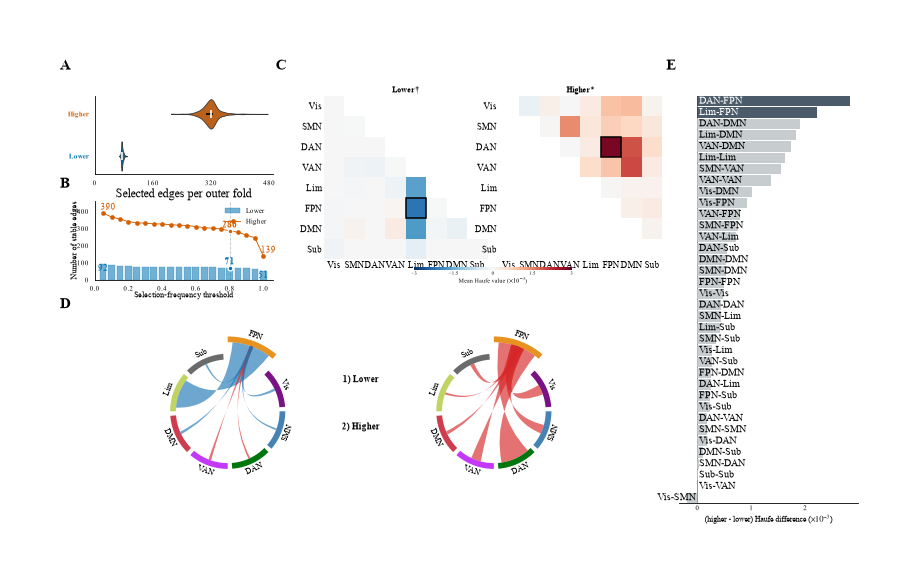


Wrote Figure 4 outputs to C:\Users\ai412\Desktop\Visualization_Figure_official_v1.1.4\3_Visualizations\results_figures:


In [9]:
# ---------------------------------------------------------------------------
# The complete canvas
# ---------------------------------------------------------------------------
def make_figure_full(export: bool = False,
                     output_dir=None,
                     state: Optional[Mapping[str, object]] = None):
    ns = state if state is not None else sys.modules['__main__'].__dict__
    fold_counts = ns['fold_counts']
    curve = ns['curve']
    block_matrices = ns['block_matrices']
    all_blocks = ns['all_blocks']
    between_range = ns['between_range']
    NETWORKS = list(ns['NETWORKS'])
    GROUPS = list(ns['GROUPS'])
    STABLE_THRESHOLD = float(ns['STABLE_THRESHOLD'])

    fig = plt.figure(figsize=(FIG_FULL_W * FIG_SCALE, FIG_FULL_H * FIG_SCALE),
                     facecolor='white')

    gs = fig.add_gridspec(
        2, 4,
        height_ratios=[B_BOT - ROW1_TOP, ROW2_BOT - ROW2_TOP],
        width_ratios=[COL_X[i][1] - COL_X[i][0] for i in range(4)],
        left=0.0, right=1.0, top=1.0, bottom=0.0,
        hspace=0.0, wspace=0.0,
    )

    ax_a = _place(fig, gs[0, 0], RECT_A)
    ax_b = _place(fig, gs[0, 0], RECT_B)
    axes_c = [_place(fig, gs[0, 1], RECT_C1),
              _place(fig, gs[0, 1], RECT_C2)]
    axes_d = [_place(fig, gs[1, 0], RECT_D1, projection='polar'),
              _place(fig, gs[1, 1], RECT_D2, projection='polar')]
    ax_e = _place(fig, gs[:, 2:4], RECT_E)

    DRAW_GROUPS = list(reversed(GROUPS))       # [lowIAT, highIAT]
    GROUP_COLORS = {GROUPS[0]: COLOR_HIGH, GROUPS[1]: COLOR_LOW}

    # A 面板
    _draw_a(ax_a, fold_counts, DRAW_GROUPS, show_title=False, show_note=True,
            yticks=[100, 200, 300, 400, 500], tick_length=0.0,
            label_pad=1.0, label_size=7.0, label_dy=-0.045)

    # B 面板
    _draw_b(ax_b, curve, GROUPS, STABLE_THRESHOLD, show_title=False,
            legend='inside', line_width=0.55, marker_size=1.8,
            threshold_marker_s=4, annotation_size=5.5, guide_width=0.5,
            tick_length=0.0, label_pad=-1.0, xlabel_pad=-0.5,
            annot_offset_high=(3, 2), annot_offset_low=(0, -4),
            annot_offset_threshold=(0, 2))

    # C 面板 (拆分成两个独立的热图)
    data_vmax = max(
        float(np.abs(block_matrices[g].loc[NETWORKS, NETWORKS].to_numpy()).max())
        for g in ['lowIAT', 'highIAT']
    )
    vmax = max(data_vmax, 0.003)

    image, _ = _draw_heatmap(
        axes_c[0], 'lowIAT', block_matrices, NETWORKS, vmax, all_blocks,
        label_size=5.5, triangle='lower'
    )
    _draw_heatmap(
        axes_c[1], 'highIAT', block_matrices, NETWORKS, vmax, all_blocks,
        label_size=5.5, triangle='upper'
    )

    fig.text(_ix((RECT_C1[0] + RECT_C1[2]) / 2), _iy(RECT_C1[1] - 0.04),
             "Lower†", ha='center', va='baseline',
             fontsize=_sc(7.6), fontweight='bold', color=INK)
    fig.text(_ix((RECT_C2[0] + RECT_C2[2]) / 2), _iy(RECT_C2[1] - 0.04),
             "Higher*", ha='center', va='baseline',
             fontsize=_sc(7.6), fontweight='bold', color=INK)

    # Colorbar
    x0, y0, x1, y1 = COLORBAR_RECT
    cax = fig.add_axes([x0 / FIG_FULL_W,
                        1.0 - y1 / FIG_FULL_H,
                        (x1 - x0) / FIG_FULL_W,
                        (y1 - y0) / FIG_FULL_H])
    cbar = fig.colorbar(image, cax=cax, orientation='horizontal')
    cbar.set_label(COLORBAR_LABEL, fontsize=_sc(5.8), color=INK, labelpad=_sc(1))
    cbar.set_ticks([-0.003, -0.0015, 0.0, 0.0015, 0.003])
    cbar.set_ticklabels(['−3', '−1.5', '0', '1.5', '3'])
    cbar.ax.tick_params(labelsize=_sc(5.0), length=_sc(0), pad=_sc(0.5), color='#000000', labelcolor='#000000')
    cbar.outline.set_visible(False)

    # D 面板 (弦图)
    _draw_c(fig, axes_d, DRAW_GROUPS, all_blocks, NETWORKS,
            show_title=False, show_panel_label=False,
            group_label_case=_group_caption, group_label_size=8.4,
            group_label_weight='bold', group_label_mode='figure',
            group_label_positions=[], # 不再使用顶部标签
            show_caption=False, show_fdr_note=False, sign_legend=False,
            label_fontsize=_sc(7.6))

    for ax, rect in zip(axes_d, (RECT_D1, RECT_D2)):
        x0, ytop, x1, ybot = rect
        ax.set_position([x0 / FIG_FULL_W, 1.0 - ybot / FIG_FULL_H,
                         (x1 - x0) / FIG_FULL_W, (ybot - ytop) / FIG_FULL_H])

    # 在 D 图中间添加 1) Lower 和 2) Higher 标签
    fig.text(_ix(D_MID), _iy(ROW2_TOP + 0.8), "1) Lower", 
             ha='center', va='baseline', fontsize=_sc(8.4), fontweight='bold', color=INK)
    fig.text(_ix(D_MID), _iy(ROW2_TOP + 1.4), "2) Higher", 
             ha='center', va='baseline', fontsize=_sc(8.4), fontweight='bold', color=INK)

    # E 面板 (瘦身贯穿，高度拉伸)
    p_values = dict(zip(between_range.block_label, between_range.p_right))
    _draw_e([ax_e], all_blocks, NETWORKS,
            caption=False, xlabel_suffix=False,
            bar_height=0.9, label_on_navy=True, label_size=6.0,
            tick_length=0.0, tick_pad=1.0, label_pad=2.0,
            p_values=p_values,
            xlabel=r'(higher - lower) Haufe difference ($\times 10^{-3}$)')

    # ---------- panel letters ---------------------------------
    _panel_label(fig, _ix(0.00), _iy(0.17), 'A')
    _panel_label(fig, _ix(0.00), _iy(B_TOP - 0.17), 'B')
    _panel_label(fig, _ix(COL1_X0 - 0.16), _iy(0.17), 'C')
    _panel_label(fig, _ix(0.00), _iy(3.20), 'D')
    _panel_label(fig, _ix(E_X0 - 0.16), _iy(0.17), 'E')

    if export:
        if output_dir is None:
            output_dir = os.environ.get(
                'FIG4_OUTPUT_DIR',
                str(RESULTS_DIR),
            )
        _save_figure_full(fig, output_dir, stem='Figure4')
    return fig

def _save_figure_full(fig, output_dir, stem='Figure4'):
    out = Path(output_dir)
    out.mkdir(parents=True, exist_ok=True)
    png = out / f'{stem}.png'
    svg = out / f'{stem}.svg'
    with mpl.rc_context({'savefig.bbox': 'standard'}):
        fig.savefig(png, dpi=300, facecolor='white')
        fig.savefig(svg, format='svg', facecolor='white',
                    metadata={'Date': None})
    print(f'  wrote {png}  ({png.stat().st_size / 1024:.0f} KB)')
    print(f'  wrote {svg}  ({svg.stat().st_size / 1024:.0f} KB)')

# --- the one-shot complete canvas ---------------------------------------
out_dir = str(RESULTS_DIR)
os.makedirs(out_dir, exist_ok=True)
os.environ['FIG4_OUTPUT_DIR'] = out_dir
figure3_full = make_figure_full(export=True, output_dir=out_dir)
plt.show()

print('\nWrote Figure 4 outputs to ' + out_dir + ':')



**Figure 4 | Predictive FC organization differed across IAT ranges.** 面板说明同上方标题；C–E 使用经典 selected-space Haufe slope。C 的组内 P 为双侧检验；E 的 P 为探索性单侧 high − low > 0 检验，零假设为两组均无 FC–IAT 关联，并非两组总体模式相等。E 对 36 模块作 BH-FDR；标注的 P 为未校正值。
